Dataset loaded successfully.
Selected sheet: Road_noise_measurements
Original dataset shape: (7386, 14)
Available columns: ['ID_MEASURING_RECORD', 'VOIVODESHIP', 'TOWN', 'MEASURING_POINT_CODE', 'LATITUDE', 'LONGITUDE', 'DATE_MEASUREMENT_START', 'DATE_MEASUREMENT_END', 'PERIOD_AND_TIME_SAMPLING', 'AVG_NOISE_LVL', 'MEU', 'Duration_hours', 'Risk_Level', 'Cumulative_MEU']

Records available after cleaning: 7386

Risk score distribution:
Risk_Score
1     988
2    3488
3    2910
Name: count, dtype: int64

TRAIN-TEST SPLIT: 80:20
Training records: 5908
Testing records: 1478
MLR Accuracy: 93.50%
MnLR Accuracy: 99.12%
XGB Accuracy: 100.00%
RF Accuracy: 100.00%

TRAIN-TEST SPLIT: 70:30
Training records: 5170
Testing records: 2216
MLR Accuracy: 93.41%
MnLR Accuracy: 99.01%
XGB Accuracy: 100.00%
RF Accuracy: 100.00%

TRAIN-TEST SPLIT: 60:40
Training records: 4431
Testing records: 2955
MLR Accuracy: 93.37%
MnLR Accuracy: 98.75%
XGB Accuracy: 100.00%
RF Accuracy: 99.86%

FINAL ACCURACY COMPARISON (%

,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,93.50,99.12,100.0,100.00
70:30,93.41,99.01,100.0,100.00
60:40,93.37,98.75,100.0,99.86


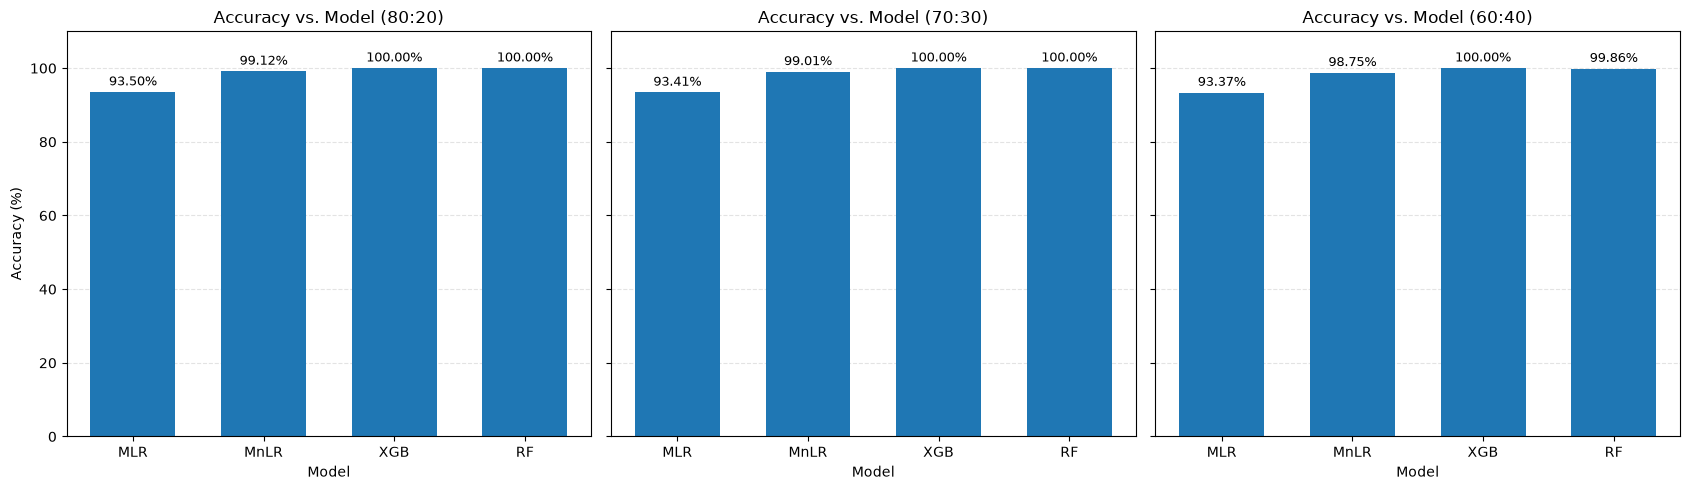

In [1]:

# ================================================================
# ROAD NOISE RISK PREDICTION
# Three Accuracy Graphs: 80:20, 70:30 and 60:40
# Dataset sheet: Road_noise_measurements
# ================================================================

# If needed, run once:
# %pip install pandas openpyxl scikit-learn matplotlib xgboost

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tkinter import Tk, filedialog

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

# ================================================================
# 1. SELECT AND LOAD THE EXCEL FILE
# ================================================================

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

FILE_PATH = filedialog.askopenfilename(
    title="Select Road Noise Excel Dataset",
    filetypes=[("Excel files", "*.xlsx *.xls")]
)

root.destroy()

if not FILE_PATH:
    raise FileNotFoundError("No Excel file was selected.")

SHEET_NAME = "Road_noise_measurements"

# Read the first row as headers.
df = pd.read_excel(
    FILE_PATH,
    sheet_name=SHEET_NAME,
    header=0
)

df.columns = df.columns.astype(str).str.strip()

print("Dataset loaded successfully.")
print("Selected sheet:", SHEET_NAME)
print("Original dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())

# ================================================================
# 2. VALIDATE COLUMNS
# ================================================================

features = [
    "TOWN",
    "LATITUDE",
    "LONGITUDE",
    "Duration_hours",
    "AVG_NOISE_LVL"
]

required_columns = features + ["Risk_Level"]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}\n"
        f"Available columns: {df.columns.tolist()}"
    )

# ================================================================
# 3. CREATE RISK SCORE
# Low = 1, Moderate = 2, High = 3
# ================================================================

risk_mapping = {
    "Low": 1,
    "Moderate": 2,
    "High": 3
}

df["Risk_Level"] = (
    df["Risk_Level"].astype(str).str.strip().str.title()
)

df["Risk_Score"] = df["Risk_Level"].map(risk_mapping)

numeric_features = [
    "LATITUDE",
    "LONGITUDE",
    "Duration_hours",
    "AVG_NOISE_LVL"
]

for col in numeric_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["TOWN"] = df["TOWN"].replace(
    r"^\s*$", np.nan, regex=True
)

# Remove rows without a valid target or town
df = df.dropna(subset=["Risk_Score", "TOWN"]).copy()
df["Risk_Score"] = df["Risk_Score"].astype(int)

X = df[features].copy()
y = df["Risk_Score"].copy()

print("\nRecords available after cleaning:", len(df))
print("\nRisk score distribution:")
print(y.value_counts().sort_index())

if set(y.unique()) != {1, 2, 3}:
    raise ValueError(
        "All three risk scores (1, 2, 3) must be present."
    )

# ================================================================
# 4. PREPROCESSING
# Fit preprocessing separately within each training split.
# ================================================================

def make_preprocessor(scale_numeric=False):

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(
            ("scaler", StandardScaler())
        )

    numeric_transformer = Pipeline(numeric_steps)

    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("town", categorical_transformer, ["TOWN"]),
        ("numeric", numeric_transformer, numeric_features)
    ])

# ================================================================
# 5. DEFINE MODELS
# ================================================================

def create_models():

    return {
        "MLR": Pipeline([
            ("preprocessor", make_preprocessor(True)),
            ("model", LinearRegression())
        ]),

        "MnLR": Pipeline([
            ("preprocessor", make_preprocessor(True)),
            ("model", LogisticRegression(
                solver="lbfgs",
                max_iter=2000,
                random_state=42
            ))
        ]),

        "XGB": Pipeline([
            ("preprocessor", make_preprocessor(False)),
            ("model", XGBClassifier(
                objective="multi:softprob",
                num_class=3,
                n_estimators=150,
                max_depth=5,
                learning_rate=0.08,
                subsample=0.9,
                colsample_bytree=0.9,
                eval_metric="mlogloss",
                random_state=42,
                n_jobs=-1
            ))
        ]),

        "RF": Pipeline([
            ("preprocessor", make_preprocessor(False)),
            ("model", RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            ))
        ])
    }

# ================================================================
# 6. TRAIN AND EVALUATE ALL THREE SPLITS
# ================================================================

splits = {
    "80:20": 0.20,
    "70:30": 0.30,
    "60:40": 0.40
}

results = {}

for split_name, test_size in splits.items():

    print(f"\n{'=' * 55}")
    print(f"TRAIN-TEST SPLIT: {split_name}")
    print(f"{'=' * 55}")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    print("Training records:", len(X_train))
    print("Testing records:", len(X_test))

    models = create_models()
    split_results = {}

    for model_name, model in models.items():

        if model_name == "XGB":
            # XGBoost expects labels 0, 1, 2.
            model.fit(X_train, y_train - 1)

            # Restore original labels 1, 2, 3.
            predictions = (
                model.predict(X_test).astype(int) + 1
            )

        else:
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            if model_name == "MLR":
                # Convert regression scores into risk classes.
                predictions = np.clip(
                    np.rint(predictions), 1, 3
                ).astype(int)

        accuracy = accuracy_score(
            y_test, predictions
        ) * 100

        split_results[model_name] = accuracy

        print(f"{model_name} Accuracy: {accuracy:.2f}%")

    results[split_name] = split_results

# ================================================================
# 7. DISPLAY ACCURACY TABLE
# ================================================================

results_df = pd.DataFrame(results).T
results_df.index.name = "Train-Test Split"

print("\nFINAL ACCURACY COMPARISON (%)")
display(results_df.round(2))

# ================================================================
# 8. GENERATE EXACTLY THREE GRAPHS
# ================================================================

model_order = ["MLR", "MnLR", "XGB", "RF"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

for ax, split_name in zip(axes, splits.keys()):

    values = [
        results[split_name][name]
        for name in model_order
    ]

    bars = ax.bar(
        model_order,
        values,
        width=0.65
    )

    ax.set_title(
        f"Accuracy vs. Model ({split_name})",
        fontsize=12
    )

    ax.set_xlabel("Model")
    ax.set_ylim(0, 110)
    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.35
    )
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

axes[0].set_ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()

# ================================================================
# END
# ================================================================


F1-Score Comparison (%)


,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,93.50,99.12,100.0,100.00
70:30,93.41,99.01,100.0,100.00
60:40,93.37,98.75,100.0,99.86


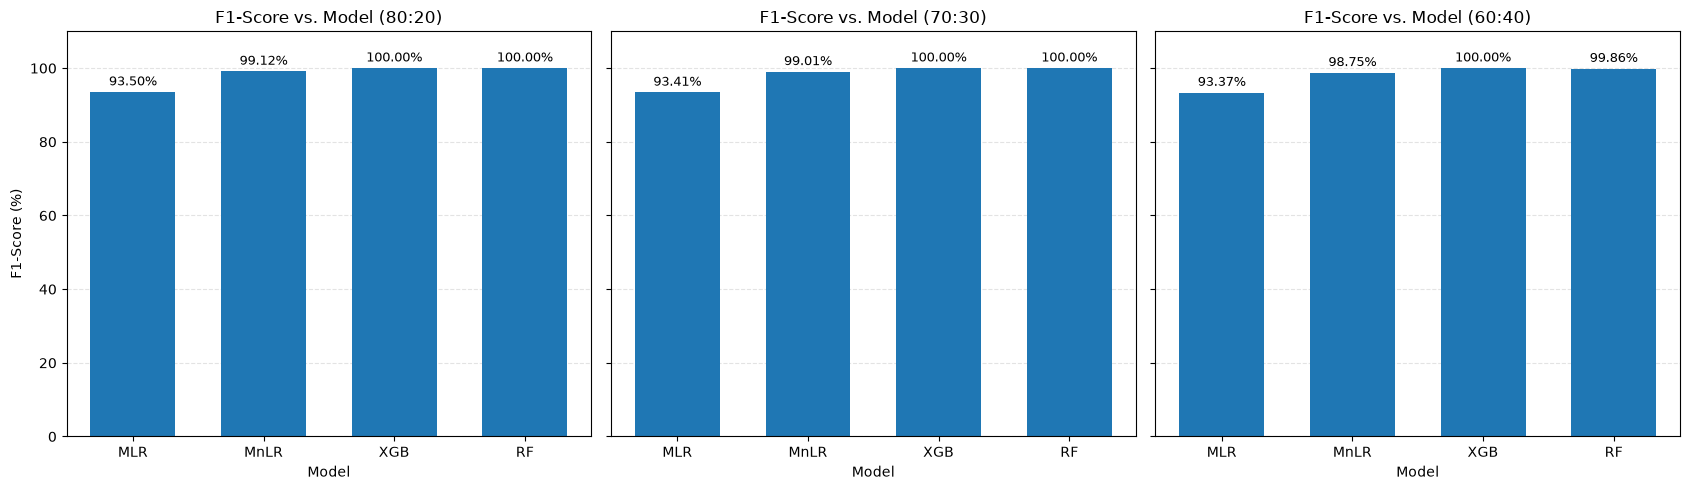

In [2]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Store F1 scores for each split
f1_results = {}

model_order = ["MLR", "MnLR", "XGB", "RF"]

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    models = create_models()
    split_f1 = {}

    for model_name, model in models.items():

        if model_name == "XGB":
            # XGBoost uses class labels 0, 1, 2
            model.fit(X_train, y_train - 1)
            predictions = model.predict(X_test).astype(int) + 1

        else:
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            if model_name == "MLR":
                predictions = np.clip(
                    np.rint(predictions), 1, 3
                ).astype(int)

        # Weighted F1-score for the three risk classes
        score = f1_score(
            y_test,
            predictions,
            labels=[1, 2, 3],
            average="weighted",
            zero_division=0
        ) * 100

        split_f1[model_name] = score

    f1_results[split_name] = split_f1

# Display F1-score results
f1_df = pd.DataFrame(f1_results).T
f1_df.index.name = "Train-Test Split"

print("F1-Score Comparison (%)")
display(f1_df.round(2))

# Generate three F1-score graphs
fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

for ax, split_name in zip(axes, splits.keys()):

    values = [
        f1_results[split_name][name]
        for name in model_order
    ]

    bars = ax.bar(
        model_order,
        values,
        width=0.65
    )

    ax.set_title(
        f"F1-Score vs. Model ({split_name})",
        fontsize=12
    )
    ax.set_xlabel("Model")
    ax.set_ylim(0, 110)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

axes[0].set_ylabel("F1-Score (%)")

plt.tight_layout()
plt.show()


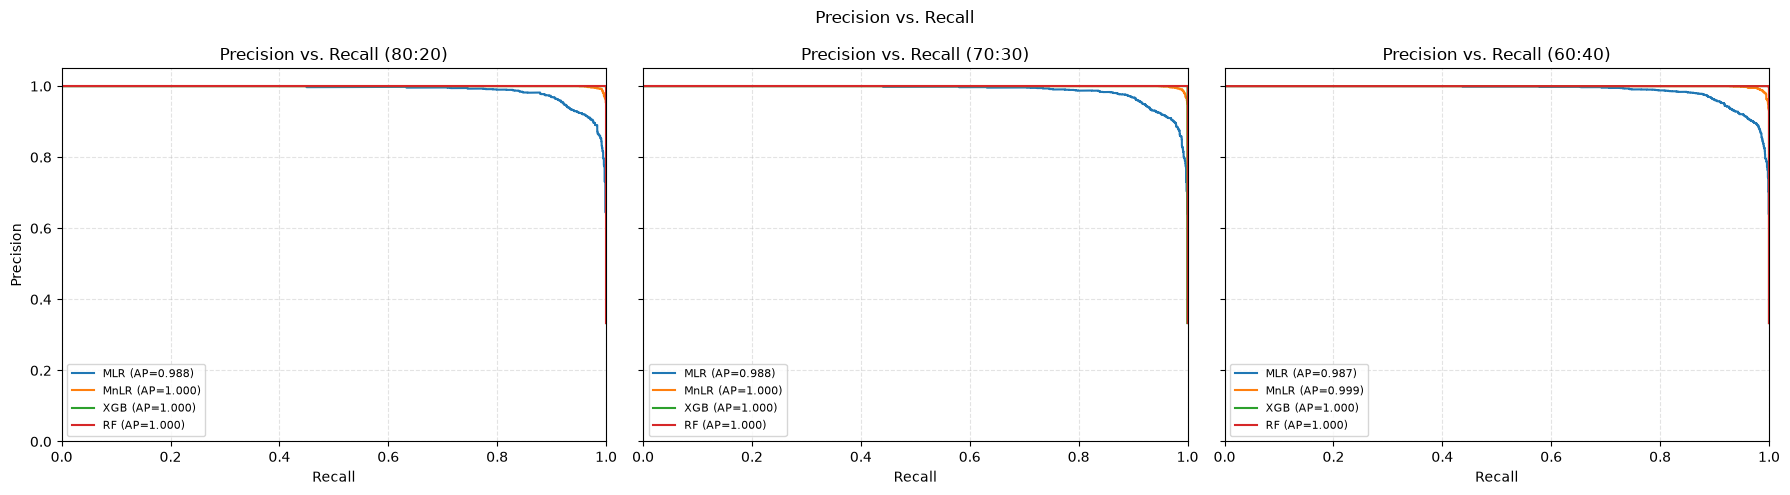

In [3]:
# ================================================================
# PRECISION-RECALL GRAPHS: ONE CURVE PER MODEL
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score

model_order = ["MLR", "MnLR", "XGB", "RF"]
class_labels = [1, 2, 3]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, (split_name, test_size) in zip(axes, splits.items()):

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    models = create_models()
    y_test_binary = label_binarize(y_test, classes=class_labels)

    for model_name in model_order:

        model = models[model_name]

        if model_name == "XGB":
            model.fit(X_train, y_train - 1)
            scores = model.predict_proba(X_test)

        elif model_name == "MLR":
            model.fit(X_train, y_train)
            raw = model.predict(X_test)

            # Convert regression predictions to continuous class scores
            scores = np.column_stack([
                np.clip(1 - np.abs(raw - c), 0, 1)
                for c in class_labels
            ])

            scores = scores / np.maximum(
                scores.sum(axis=1, keepdims=True), 1e-12
            )

        else:
            model.fit(X_train, y_train)
            probabilities = model.predict_proba(X_test)
            fitted_classes = model.named_steps["model"].classes_

            scores = np.column_stack([
                probabilities[:, list(fitted_classes).index(c)]
                for c in class_labels
            ])

        # Micro-average across all three classes
        precision, recall, _ = precision_recall_curve(
            y_test_binary.ravel(),
            scores.ravel()
        )

        ap = average_precision_score(
            y_test_binary,
            scores,
            average="micro"
        )

        ax.plot(
            recall,
            precision,
            linewidth=1.5,
            label=f"{model_name} (AP={ap:.3f})"
        )

    ax.set_title(f"Precision vs. Recall ({split_name})")
    ax.set_xlabel("Recall")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(fontsize=8, loc="lower left")

axes[0].set_ylabel("Precision")

plt.suptitle("Precision vs. Recall")
plt.tight_layout()
plt.show()

In [4]:
splits = {
    "80:20": 0.20,
    "70:30": 0.30,
    "60:40": 0.40
}

Calculating ROC curves for 80:20...
Calculating ROC curves for 70:30...
Calculating ROC curves for 60:40...


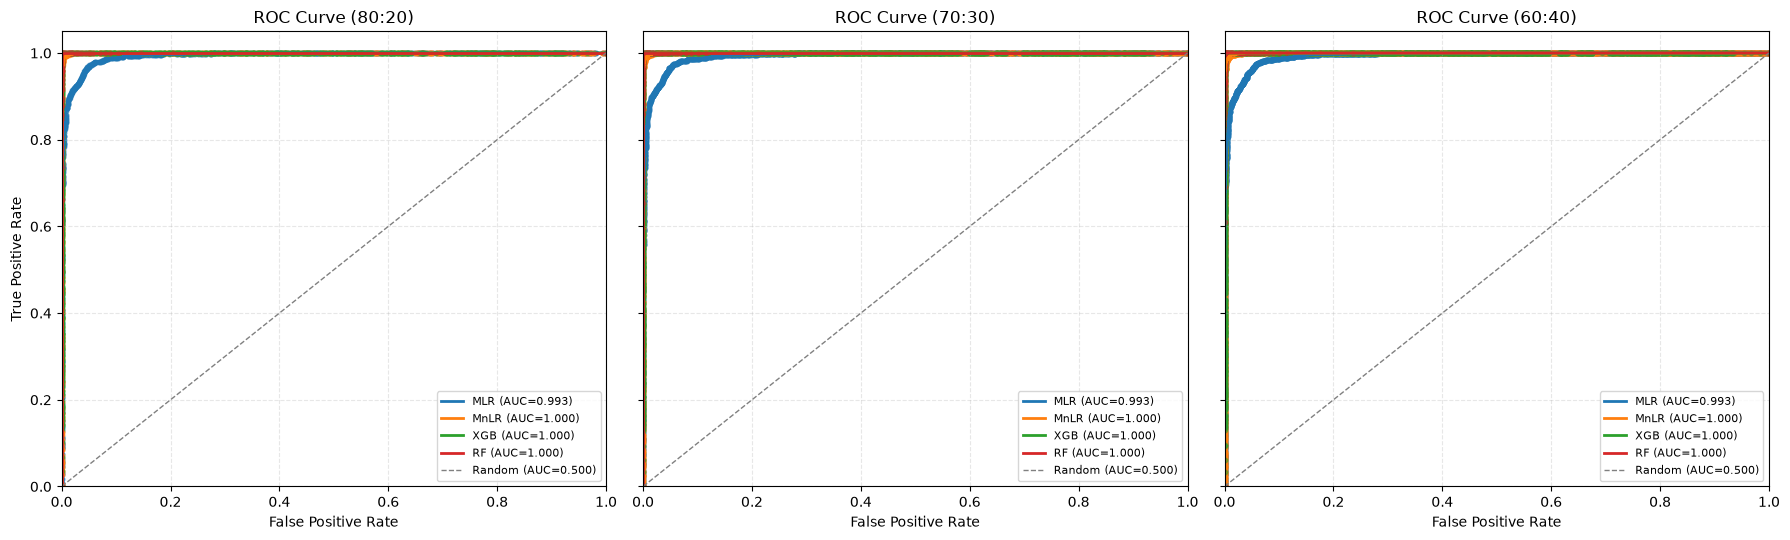

Micro-average ROC-AUC scores:


,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,0.9932,0.9998,1.0,1.0
70:30,0.9927,0.9998,1.0,1.0
60:40,0.9927,0.9997,1.0,1.0


In [5]:
# ============================================================
# ROC CURVES FOR FOUR MODELS
# 80:20, 70:30 and 60:40 train-test splits
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

classes = [1, 2, 3]
model_order = ["MLR", "MnLR", "XGB", "RF"]

roc_results = {}

for split_name, test_size in splits.items():

    print(f"Calculating ROC curves for {split_name}...")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    y_test_binary = label_binarize(y_test, classes=classes)
    split_results = {}

    for name, model in create_models().items():

        if name == "XGB":
            model.fit(X_train, y_train - 1)
            raw_scores = model.predict_proba(X_test)
            model_classes = [1, 2, 3]

        elif name == "MLR":
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            # Convert continuous predictions to class-closeness scores
            raw_scores = np.column_stack([
                -np.abs(predictions - cls) for cls in classes
            ])
            model_classes = classes

        else:
            model.fit(X_train, y_train)
            raw_scores = model.predict_proba(X_test)
            model_classes = model.named_steps["model"].classes_

        # Align scores with classes 1, 2, 3
        scores = np.zeros((len(X_test), len(classes)))

        for j, cls in enumerate(model_classes):
            scores[:, int(cls) - 1] = raw_scores[:, j]

        # Micro-average ROC curve
        fpr, tpr, _ = roc_curve(
            y_test_binary.ravel(),
            scores.ravel()
        )

        roc_auc = auc(fpr, tpr)

        split_results[name] = {
            "fpr": fpr,
            "tpr": tpr,
            "auc": roc_auc
        }

    roc_results[split_name] = split_results

# ============================================================
# PLOT THREE ROC GRAPHS
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5.5),
    sharey=True
)

for ax, split_name in zip(axes, splits.keys()):

    for name in model_order:

        result = roc_results[split_name][name]
        fpr = result["fpr"]
        tpr = result["tpr"]
        model_auc = result["auc"]

        # Mark ROC points and connect them
        ax.scatter(fpr, tpr, s=10, alpha=0.5)
        ax.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{name} (AUC={model_auc:.3f})"
        )

    # Random-classifier reference
    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        linewidth=1,
        color="gray",
        label="Random (AUC=0.500)"
    )

    ax.set_title(f"ROC Curve ({split_name})")
    ax.set_xlabel("False Positive Rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend(fontsize=8, loc="lower right")

axes[0].set_ylabel("True Positive Rate")

plt.tight_layout()
plt.show()

# ============================================================
# DISPLAY AUC SUMMARY
# ============================================================

auc_table = pd.DataFrame({
    split_name: {
        name: roc_results[split_name][name]["auc"]
        for name in model_order
    }
    for split_name in splits
}).T

auc_table.index.name = "Train-Test Split"

print("Micro-average ROC-AUC scores:")
display(auc_table.round(4))


Evaluating 80:20 split

Evaluating 70:30 split

Evaluating 60:40 split

Mean Accuracy (%) Across Five Random Seeds


,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,94.14,98.93,100.0,99.97
70:30,93.84,98.78,100.0,99.95
60:40,93.52,98.63,100.0,99.88



Standard Deviation (%)


,MLR,MnLR,XGB,RF
Train-Test Split,,,,
80:20,0.797,0.175,0.0,0.061
70:30,0.475,0.150,0.0,0.049
60:40,0.374,0.085,0.0,0.121



Accuracy for Every Individual Run


,Split,Model,Seed,Accuracy (%)
0,80:20,MLR,42,93.5047
1,80:20,MLR,43,93.3694
2,80:20,MLR,44,94.9932
3,80:20,MLR,45,93.8430
4,80:20,MLR,46,94.9932
5,80:20,MnLR,42,99.1204
6,80:20,MnLR,43,98.6468
7,80:20,MnLR,44,98.9851
8,80:20,MnLR,45,98.9851
9,80:20,MnLR,46,98.9175


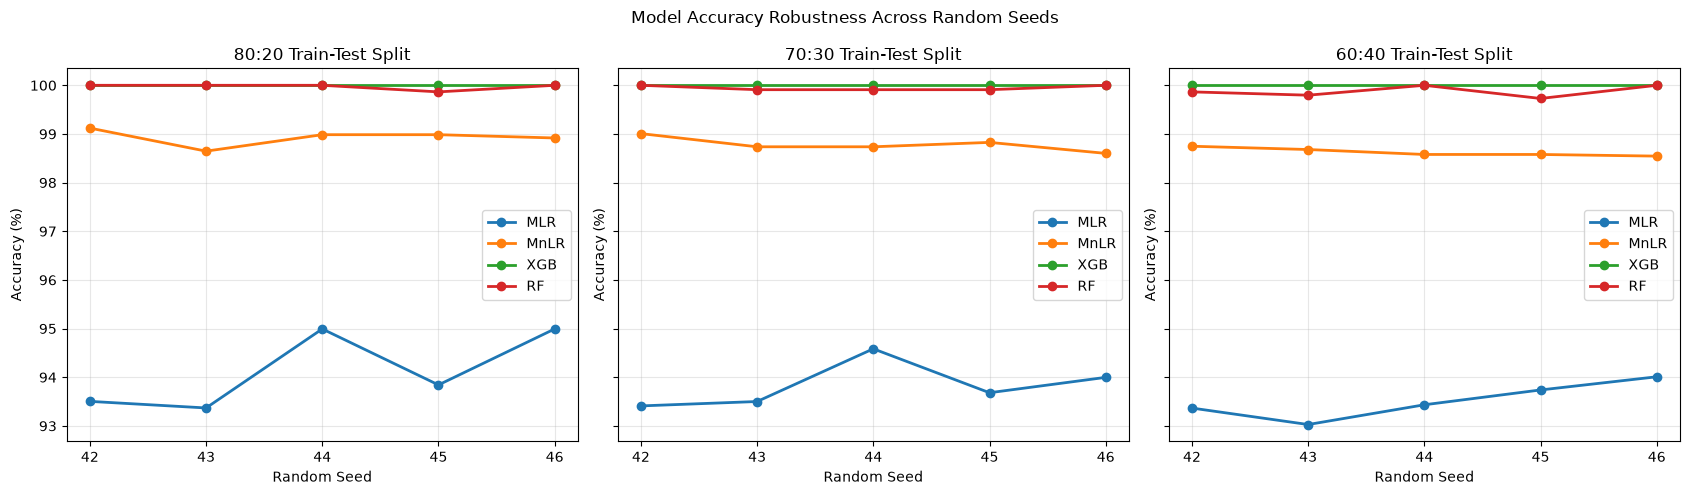

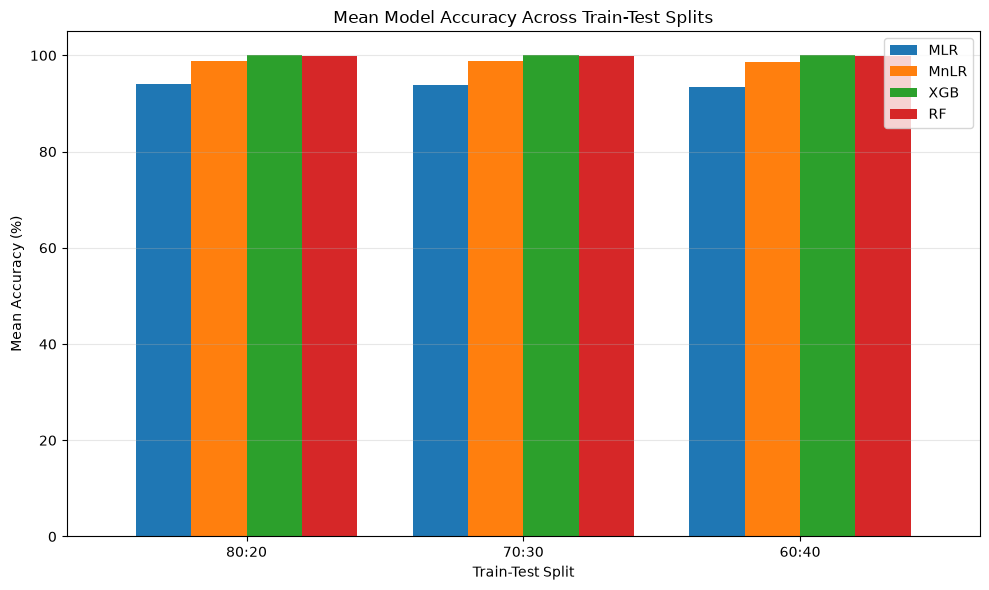

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# ==================================================
# 1. CONFIGURATION
# ==================================================

features = [
    "TOWN",
    "LATITUDE",
    "LONGITUDE",
    "Duration_hours",
    "AVG_NOISE_LVL"
]

target = "Risk_Score"

model_order = ["MLR", "MnLR", "XGB", "RF"]

splits = {
    "80:20": 0.20,
    "70:30": 0.30,
    "60:40": 0.40
}

random_seeds = [42, 43, 44, 45, 46]

data = df[features + [target]].dropna().copy()

X = data[features]
y = data[target].astype(int)

# Store accuracy for each model, split and seed
robustness_results = {
    split: {model: [] for model in model_order}
    for split in splits
}

# ==================================================
# 2. RUN ROBUSTNESS EXPERIMENT
# ==================================================

for split_name, test_size in splits.items():

    print(f"\nEvaluating {split_name} split")

    for seed in random_seeds:

        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=test_size,
            random_state=seed,
            stratify=y
        )

        models = create_models()

        for model_name in model_order:

            model = models[model_name]

            if model_name == "XGB":
                model.fit(X_train, y_train - 1)
                predictions = model.predict(X_test).astype(int) + 1

            elif model_name == "MLR":
                model.fit(X_train, y_train)
                predictions = np.clip(
                    np.rint(model.predict(X_test)), 1, 3
                ).astype(int)

            else:
                model.fit(X_train, y_train)
                predictions = model.predict(X_test)

            accuracy = accuracy_score(
                y_test, predictions
            ) * 100

            robustness_results[split_name][model_name].append(
                accuracy
            )

# ==================================================
# 3. CALCULATE MEAN ACCURACY AND STANDARD DEVIATION
# ==================================================

mean_results = pd.DataFrame(
    {
        split: {
            model: np.mean(robustness_results[split][model])
            for model in model_order
        }
        for split in splits
    }
).T

std_results = pd.DataFrame(
    {
        split: {
            model: np.std(
                robustness_results[split][model],
                ddof=1
            )
            for model in model_order
        }
        for split in splits
    }
).T

mean_results.index.name = "Train-Test Split"
std_results.index.name = "Train-Test Split"

print("\nMean Accuracy (%) Across Five Random Seeds")
display(mean_results.round(2))

print("\nStandard Deviation (%)")
display(std_results.round(3))

# ==================================================
# 4. INDIVIDUAL MODEL ACCURACY
# ==================================================

rows = []

for split in splits:
    for model in model_order:
        for seed, accuracy in zip(
            random_seeds,
            robustness_results[split][model]
        ):
            rows.append({
                "Split": split,
                "Model": model,
                "Seed": seed,
                "Accuracy (%)": accuracy
            })

individual_results = pd.DataFrame(rows)

print("\nAccuracy for Every Individual Run")
display(individual_results.round(4))

# ==================================================
# 5. ROBUSTNESS GRAPH
# ==================================================

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)

for ax, split in zip(axes, splits):

    for model in model_order:
        ax.plot(
            random_seeds,
            robustness_results[split][model],
            marker="o",
            linewidth=2,
            label=model
        )

    ax.set_title(f"{split} Train-Test Split")
    ax.set_xlabel("Random Seed")
    ax.set_ylabel("Accuracy (%)")
    ax.set_xticks(random_seeds)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Model Accuracy Robustness Across Random Seeds")
plt.tight_layout()
plt.show()

# ==================================================
# 6. MEAN ACCURACY COMPARISON
# ==================================================

ax = mean_results.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.8
)

ax.set_title("Mean Model Accuracy Across Train-Test Splits")
ax.set_xlabel("Train-Test Split")
ax.set_ylabel("Mean Accuracy (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

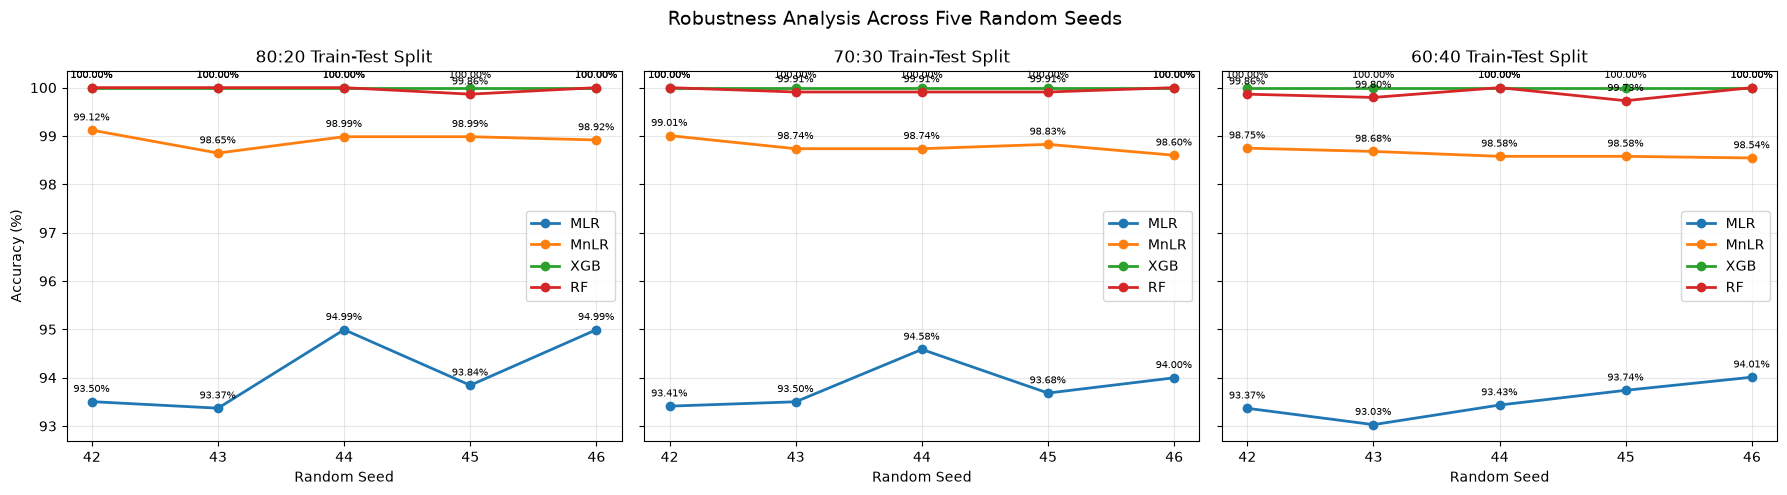

In [11]:
import matplotlib.pyplot as plt

model_order = ["MLR", "MnLR", "XGB", "RF"]
random_seeds = [42, 43, 44, 45, 46]
splits = ["80:20", "70:30", "60:40"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, split in zip(axes, splits):
    for model in model_order:
        accuracies = robustness_results[split][model]

        ax.plot(
            random_seeds,
            accuracies,
            marker="o",
            linewidth=2,
            label=model
        )

        # Display accuracy values beside points
        for seed, accuracy in zip(random_seeds, accuracies):
            ax.annotate(
                f"{accuracy:.2f}%",
                (seed, accuracy),
                textcoords="offset points",
                xytext=(0, 7),
                ha="center",
                fontsize=7
            )

    ax.set_title(f"{split} Train-Test Split")
    ax.set_xlabel("Random Seed")
    ax.set_xticks(random_seeds)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Accuracy (%)")
fig.suptitle(
    "Robustness Analysis Across Five Random Seeds",
    fontsize=14
)

plt.tight_layout()
plt.show()

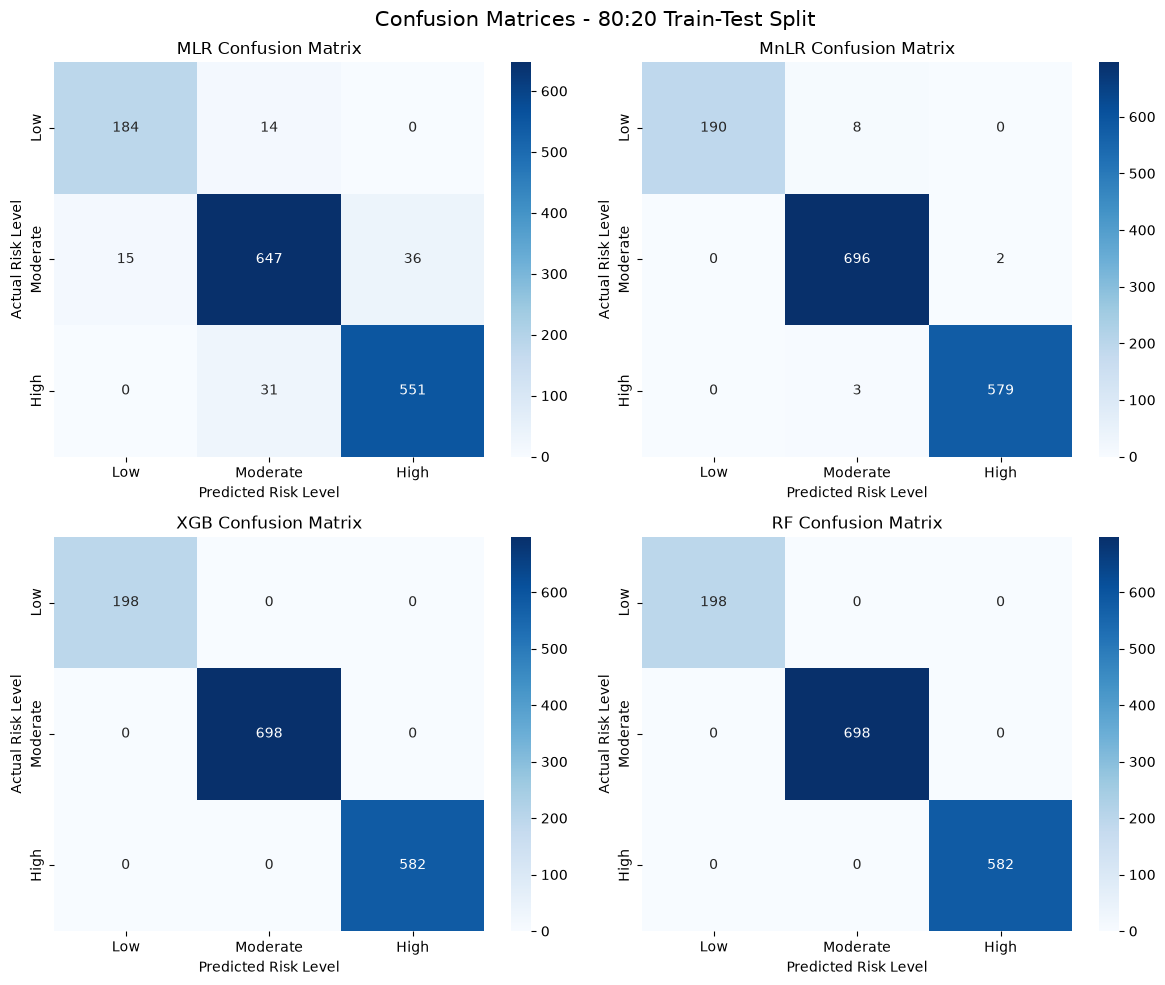

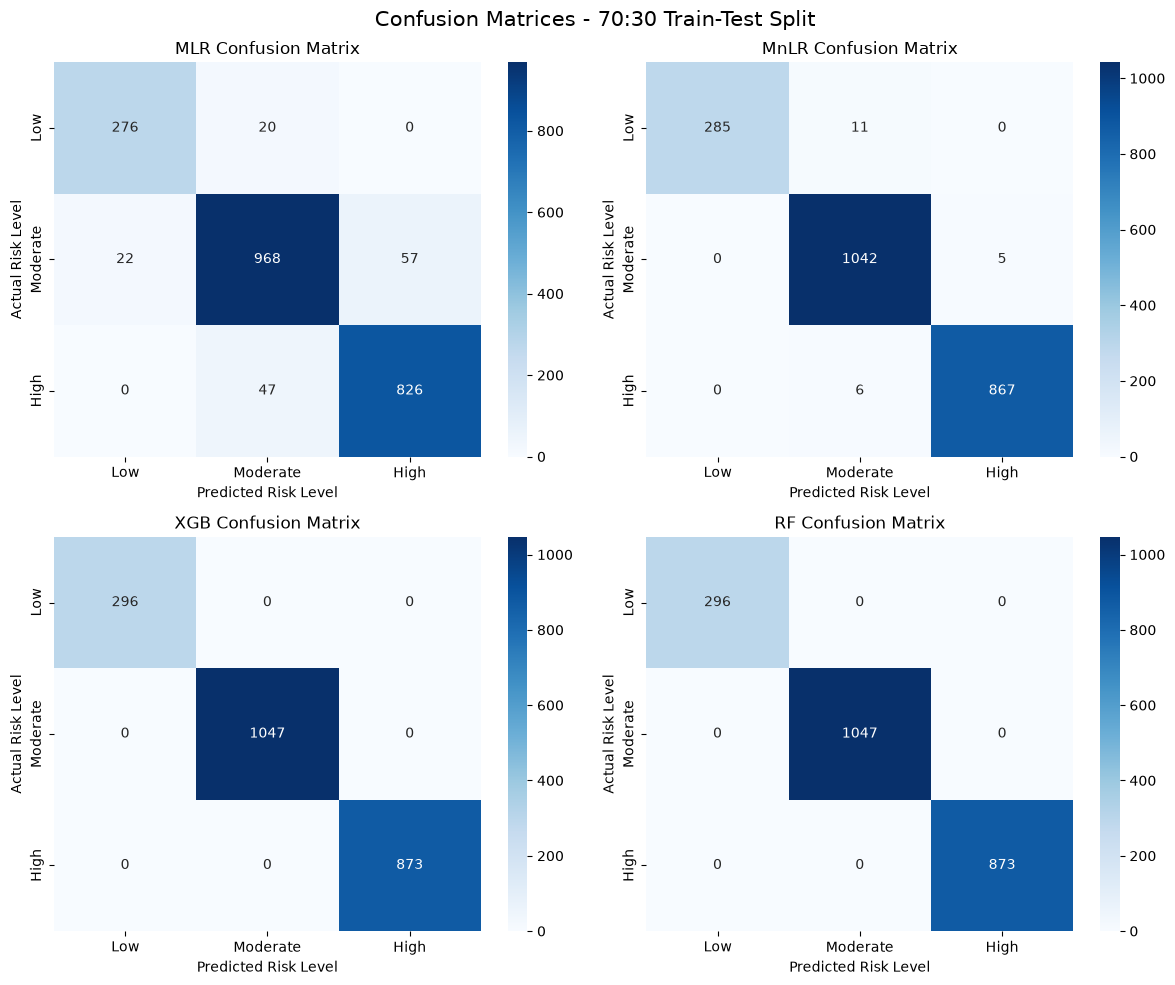

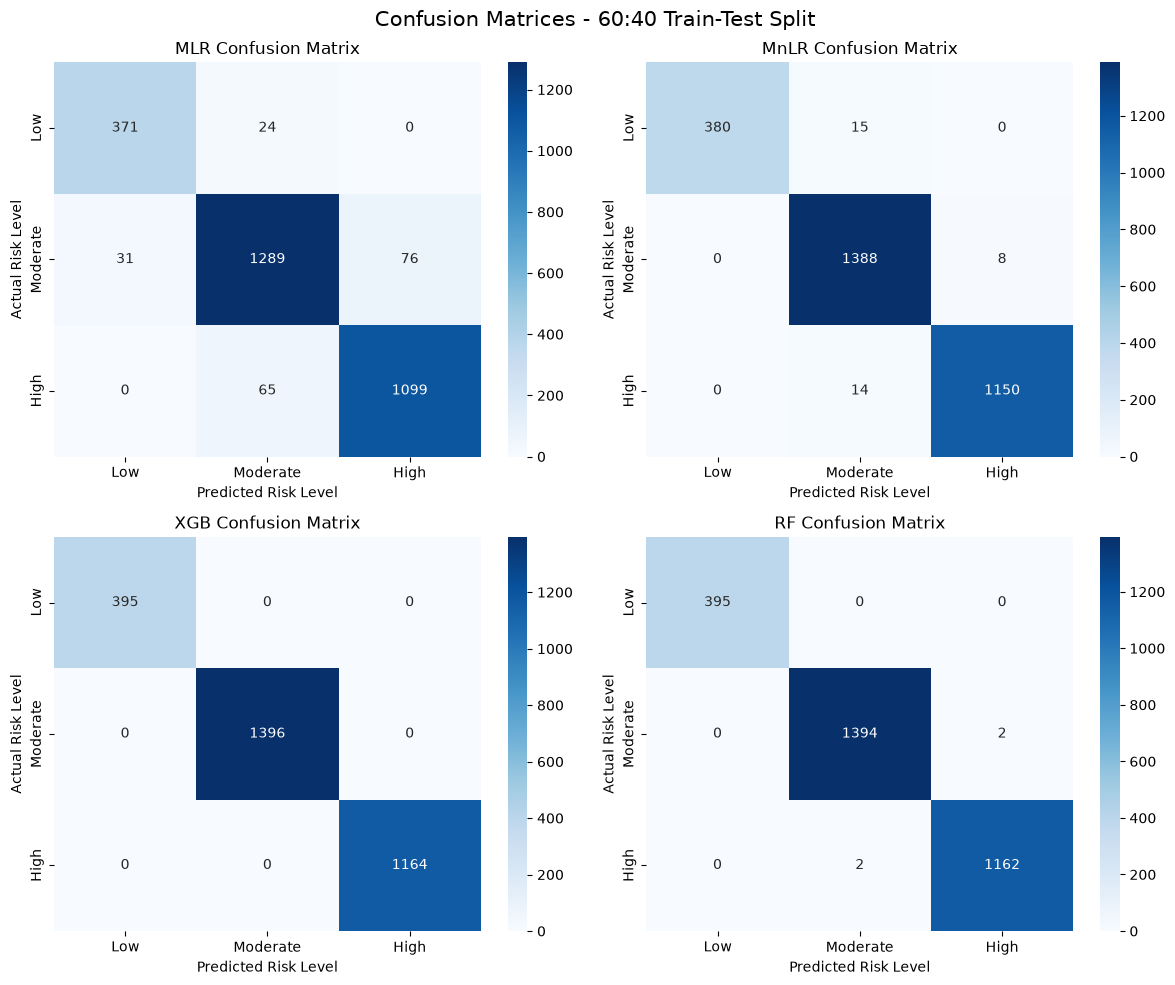

In [15]:
# ================================================================
# CONFUSION MATRIX FOR ALL MODELS AND TRAIN-TEST SPLITS
# ================================================================

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

model_order = ["MLR", "MnLR", "XGB", "RF"]
class_labels = [1, 2, 3]
class_names = ["Low", "Moderate", "High"]

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    models = create_models()

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.flatten()

    for ax, model_name in zip(axes, model_order):

        model = models[model_name]

        if model_name == "XGB":
            model.fit(X_train, y_train - 1)
            y_pred = model.predict(X_test).astype(int) + 1

        else:
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            if model_name == "MLR":
                y_pred = np.clip(
                    np.rint(y_pred), 1, 3
                ).astype(int)

        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=class_labels
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names,
            ax=ax
        )

        ax.set_title(f"{model_name} Confusion Matrix")
        ax.set_xlabel("Predicted Risk Level")
        ax.set_ylabel("Actual Risk Level")

    plt.suptitle(
        f"Confusion Matrices - {split_name} Train-Test Split",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()